In [8]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# File path (adjust if needed)
PATH = "../../statsbomb_pipeline/data/processed/team/team_season.csv"

# Load data
df = pd.read_csv(PATH)

# ---- Target and predictors ----
target_col = "xg_for"

# All numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Drop target + IDs / junk predictors
drop_cols = [
    target_col,
    "team_id",
    "matches_played",
    "wins",
    "losses",
    "draws",
    "xg_per_match"
]

predictor_cols = [c for c in numeric_cols if c not in drop_cols and c in df.columns]

print("Target:", target_col)
print("Num predictors:", len(predictor_cols))
print("Predictors:", predictor_cols)

# X / y
X = df[predictor_cols].copy()
y = df[target_col].copy()

# Train / test split (80 / 20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])


Target: xg_for
Num predictors: 13
Predictors: ['goals_for', 'goals_against', 'shots_for', 'passes_for', 'carries_for', 'ppa_for', 'f3_entries_for', 'xthreat_for', 'goal_diff', 'xthreat_per_match', 'goals_per_match', 'ppa_per_match', 'f3_entries_per_match']
Train size: 16
Test size: 4


In [9]:
def run_univariate_linear_regression(feature_name, X_train, X_test, y_train, y_test):
    """
    Fit a simple linear regression: y ~ feature_name.
    Returns metrics and fitted model.
    """
    model = LinearRegression()

    # Use only this feature (kept as 2D array)
    Xtr = X_train[[feature_name]]
    Xte = X_test[[feature_name]]

    model.fit(Xtr, y_train)

    # Predictions
    y_pred_train = model.predict(Xtr)
    y_pred_test = model.predict(Xte)

    # Metrics
    r2_train = r2_score(y_train, y_pred_train)
    r2_test = r2_score(y_test, y_pred_test)

    # Manual RMSE since squared=False is not supported
    rmse_train = mean_squared_error(y_train, y_pred_train) ** 0.5
    rmse_test = mean_squared_error(y_test, y_pred_test) ** 0.5

    results = {
        "feature": feature_name,
        "r2_train": r2_train,
        "r2_test": r2_test,
        "rmse_train": rmse_train,
        "rmse_test": rmse_test,
        "model": model,
    }

    return results


In [10]:
all_results = []
models = {}

for feat in predictor_cols:
    res = run_univariate_linear_regression(feat, X_train, X_test, y_train, y_test)

    # Save model separately
    models[feat] = res["model"]

    # Save metrics (excluding the model object) for tabular view
    metrics_row = {k: v for k, v in res.items() if k != "model"}
    all_results.append(metrics_row)

results_df = pd.DataFrame(all_results)

# Pretty view
results_df = results_df.sort_values("r2_test", ascending=False)
display(results_df)


,feature,r2_train,r2_test,rmse_train,rmse_test
0,goals_for,0.936557,0.777671,2.405103,5.512281
10,goals_per_match,0.936557,0.777671,2.405103,5.512281
8,goal_diff,0.935701,0.668142,2.421275,6.734558
2,shots_for,0.888713,0.408676,3.185407,8.989712
9,xthreat_per_match,0.444570,0.370331,7.116338,9.276612
7,xthreat_for,0.444570,0.370331,7.116338,9.276612
1,goals_against,0.558555,0.243724,6.344253,10.166545
11,ppa_per_match,0.635355,0.096294,5.766033,11.113398
5,ppa_for,0.635355,0.096294,5.766033,11.113398
6,f3_entries_for,0.547490,-0.717287,6.423273,15.319856


In [11]:
# sort by best test R^2
best_by_r2 = results_df.sort_values("r2_test", ascending=False).reset_index(drop=True)
display(best_by_r2.head(10))

best_feature = best_by_r2.loc[0, "feature"]
best_model = models[best_feature]

print(f"Best univariate predictor of {target_col}: {best_feature}")
print(f"R^2 (train): {best_by_r2.loc[0, 'r2_train']:.4f}")
print(f"R^2 (test):  {best_by_r2.loc[0, 'r2_test']:.4f}")
print(f"RMSE (train): {best_by_r2.loc[0, 'rmse_train']:.4f}")
print(f"RMSE (test):  {best_by_r2.loc[0, 'rmse_test']:.4f}")


,feature,r2_train,r2_test,rmse_train,rmse_test
0,goals_for,0.936557,0.777671,2.405103,5.512281
1,goals_per_match,0.936557,0.777671,2.405103,5.512281
2,goal_diff,0.935701,0.668142,2.421275,6.734558
3,shots_for,0.888713,0.408676,3.185407,8.989712
4,xthreat_per_match,0.444570,0.370331,7.116338,9.276612
5,xthreat_for,0.444570,0.370331,7.116338,9.276612
6,goals_against,0.558555,0.243724,6.344253,10.166545
7,ppa_per_match,0.635355,0.096294,5.766033,11.113398
8,ppa_for,0.635355,0.096294,5.766033,11.113398
9,f3_entries_for,0.547490,-0.717287,6.423273,15.319856


Best univariate predictor of xg_for: goals_for
R^2 (train): 0.9366
R^2 (test):  0.7777
RMSE (train): 2.4051
RMSE (test):  5.5123


/home/mauposad/miniforge3/envs/data-mining/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


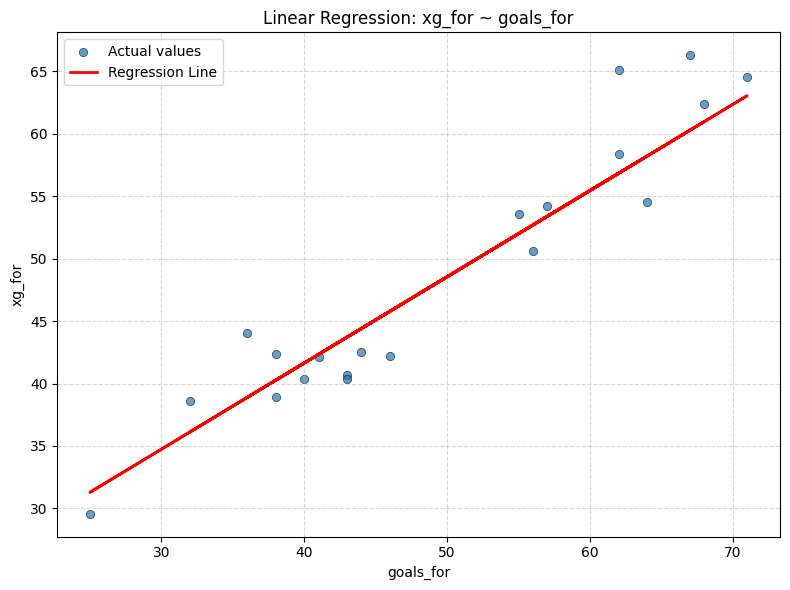

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Extract train + test for plotting
X_all = pd.concat([X_train[[best_feature]], X_test[[best_feature]]], axis=0)
y_all = pd.concat([y_train, y_test], axis=0)

# Fit-line values sorted along x-axis
x_sorted = np.sort(X_all[best_feature].values.reshape(-1, 1))
y_pred_line = best_model.predict(x_sorted)

plt.figure(figsize=(8, 6))

# Scatter: actual xg_for vs the best predictor
plt.scatter(
    X_all[best_feature],
    y_all,
    alpha=0.7,
    edgecolor="black",
    linewidth=0.5,
    label="Actual values"
)

# Regression line
plt.plot(
    x_sorted,
    y_pred_line,
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.title(f"Linear Regression: xg_for ~ {best_feature}")
plt.xlabel(best_feature)
plt.ylabel("xg_for")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


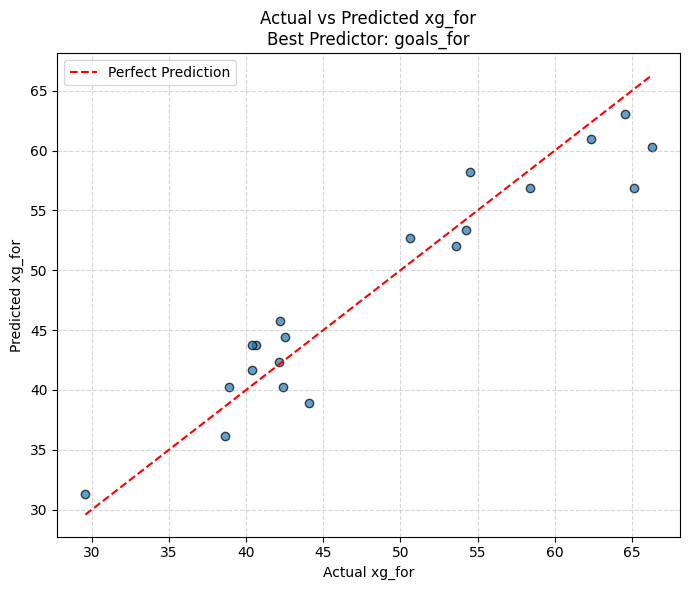

In [13]:
# Predictions
y_pred_all = best_model.predict(X_all[[best_feature]])

plt.figure(figsize=(7, 6))
plt.scatter(y_all, y_pred_all, alpha=0.7, edgecolor="black")
plt.plot([y_all.min(), y_all.max()], [y_all.min(), y_all.max()], "r--", label="Perfect Prediction")

plt.xlabel("Actual xg_for")
plt.ylabel("Predicted xg_for")
plt.title(f"Actual vs Predicted xg_for\nBest Predictor: {best_feature}")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()
